# Working with tables in R (tidyverse)
*INRAe-IFB-INSERM Bioinformatics School 2026*

* Elodie Girard - Institut Curie

<style>
/* Slide text size and vertical overflow */
.reveal { font-size: 26px !important; }
.reveal .slides section.stack { overflow: visible !important; max-height: none !important; }
.reveal .slides section:not(.stack) { max-height: 100% !important; overflow-y: auto !important; }
.reveal img { max-height: 255px; width: auto; }
/* Fenced markdown blocks */
.reveal pre code { font-size: 1.2em !important; line-height: 1.4 !important; }
/* Code cell outputs */
.jp-OutputArea-output, .jp-OutputArea-output pre {
    font-size: 18px !important; max-height: 290px !important;
    overflow-y: auto !important; overflow-x: auto !important;
    white-space: pre !important; width: 100% !important; box-sizing: border-box !important;
}
.jp-OutputArea-output table, .jp-OutputArea-output table th, .jp-OutputArea-output table td { font-size: 16px !important; }
/* Code cell inputs */
.jp-InputArea .highlight { overflow-x: auto !important; max-width: 100%; display: block; }
.jp-InputArea .highlight pre { font-size: 18px !important; white-space: pre !important; }
</style>

**Goal of this session**

Learn the few tidyverse tools needed to read, reshape, filter, summarise and plot a table.
The same verbs will be used in the next notebook to analyse a VCF file.

| Step | Package | Main verbs |
|---|---|---|
| Reshape | `tidyr` | `unite`, `separate`, `pivot_longer`, `pivot_wider` |
| Transform | `dplyr` | `filter`, `select`, `mutate`, `group_by`, `summarise`, `*_join` |
| Text | `stringr` | `str_detect`, `str_length`, `str_extract` |
| Plot | `ggplot2` | `geom_point`, `geom_line`, `geom_histogram`, `geom_density` |

Load the packages once at the top of the notebook (install them first if needed with `install.packages("tidyverse")`).

In [4]:
suppressPackageStartupMessages({
  library(tibble)
  library(tidyr)
  library(dplyr)
  library(stringr)
  library(ggplot2)
})

## I - Reminder: R objects

**Variable**: stores one numeric value or one character string.

In [1]:
string <- "hello world"
value  <- 10
string
value

[1] "hello world"

[1] 10

**Vector**: stores a series of values of the **same type** (numeric, character, logical...).

In [3]:
vect <- c(1, 2, 11, 12)
vect
vect[2]       # second element
vect[vect > 5]  # logical indexing

[1]  1  2 11 12

[1] 2

[1] 11 12

**Matrix**: a 2D table of values of the **same type**.

In [4]:
mat <- matrix(c(1, 2, 11, 12), nrow = 2, ncol = 2, byrow = TRUE)
mat

1,2
11,12


**data.frame**: a 2D table whose columns can have **different types**.

In [9]:
df <- data.frame(num = c(1, 11), chr = c("x", "y"))
df
str(df)

num,chr
<dbl>,<chr>
1,x
11,y


'data.frame':	2 obs. of  2 variables:
 $ num: num  1 11
 $ chr: chr  "x" "y"


**List**: stores objects of **different nature** (here a vector, a matrix and a data.frame).

In [6]:
lst <- list(vector = vect, matrix = mat, dataframe = df)
str(lst)
lst$dataframe   # or lst[["dataframe"]]

List of 3
 $ vector   : num [1:4] 1 2 11 12
 $ matrix   : num [1:2, 1:2] 1 11 2 12
 $ dataframe:'data.frame':	2 obs. of  2 variables:
  ..$ num: num [1:2] 1 11
  ..$ chr: chr [1:2] "x" "y"


num,chr
<dbl>,<chr>
1,x
11,y


<div style="background-color: #fff3cd; border-left: 6px solid #ffc107; color: #856404; padding: 10px; border-radius: 4px;">
    ⚠️ <strong>Warning</strong><br>
    Do not name a variable <code>list</code>, <code>c</code>, <code>df</code> or <code>data</code>: it hides an existing R function. We use <code>lst</code> here.
</div>

**S3 / S4 objects (object-oriented programming)**: store structured data with named **slots**.

This is what `vcfR` does: a VCF is stored in an S4 object with the slots `@meta`, `@fix` and `@gt`.

In [10]:
# A minimal S4 class describing a variant
setClass("Variant", representation(chrom = "character", pos = "numeric"))
v <- new("Variant", chrom = "NC_037329.1", pos = 90572569)

isS4(v)
slotNames(v)
v@pos          # access a slot with @

[1] TRUE

[1] "chrom" "pos"

[1] 90572569

## II - The tidyverse and tidy data

<a href="https://www.tidyverse.org">tidyverse.org</a>: a collection of R packages that share the same design and the same data structures.

**Tidy data** is a way to organise tabular data in a consistent structure across packages:

1. each **variable** is a column,
2. each **observation** is a row,
3. each **value** is a cell.

**Tibbles** are the table format of the `tibble` package.
They inherit from the `data.frame` class but have improved behaviour: compact printing with column types, no silent conversion of strings to factors, no partial column matching.

In [11]:
tb <- tibble(
  name  = c("dupont_lepetit", "jean_legrand", "toto_tutu"),
  month = c("09", "11", "04"),
  year  = c(1945, 2000, 1820)
)
tb
class(tb)

name,month,year
<chr>,<chr>,<dbl>
dupont_lepetit,09,1945
jean_legrand,11,2000
toto_tutu,04,1820


[1] "tbl_df"     "tbl"        "data.frame"

### Printing a tibble: compact, with the type of each column

In [9]:
print(as_tibble(iris), n = 5)   # a tibble never floods the console: 10 rows by default, here 5

# A tibble: 150 × 5
  Sepal.Length Sepal.Width Petal.Length Petal.Width Species
         <dbl>       <dbl>        <dbl>       <dbl> <fct>  
1          5.1         3.5          1.4         0.2 setosa 
2          4.9         3            1.4         0.2 setosa 
3          4.7         3.2          1.3         0.2 setosa 
4          4.6         3.1          1.5         0.2 setosa 
5          5           3.6          1.4         0.2 setosa 
# ℹ 145 more rows


## III - Data tidying with `tidyr`

Cheat sheet: <a href="https://raw.githubusercontent.com/rstudio/cheatsheets/main/tidyr.pdf">tidyr.pdf</a>

```r
install.packages("tidyr")
library(tidyr)
```

### `unite()`: merge several columns into one

`unite(data, col, ..., sep = "_", remove = TRUE)`

In [10]:
tb

name,month,year
<chr>,<chr>,<dbl>
dupont_lepetit,09,1945
jean_legrand,11,2000
toto_tutu,04,1820


In [11]:
unite(tb, col = "birth", month, year, sep = "/", remove = TRUE)

name,birth
<chr>,<chr>
dupont_lepetit,09/1945
jean_legrand,11/2000
toto_tutu,04/1820


### `separate()`: split one column into several

`separate(data, col, into, sep, remove = TRUE)`

In [12]:
separate(tb, col = "name", into = c("Fname", "Lname"), sep = "_", remove = TRUE)

Fname,Lname,month,year
<chr>,<chr>,<chr>,<dbl>
dupont,lepetit,09,1945
jean,legrand,11,2000
toto,tutu,04,1820


### `separate_wider_delim()`: the newer alternative

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    Since <code>tidyr</code> 1.3.0, <code>separate()</code> is superseded by <code>separate_wider_delim()</code> (stricter: it reports rows that do not split as expected). <code>separate()</code> still works and is widely used, including in the next notebook.
</div>

In [13]:
separate_wider_delim(tb, cols = name, delim = "_", names = c("Fname", "Lname"))

Fname,Lname,month,year
<chr>,<chr>,<chr>,<dbl>
dupont,lepetit,09,1945
jean,legrand,11,2000
toto,tutu,04,1820


### Chaining with the pipe

The pipe passes the result of the left side as the **first argument** of the function on the right side.
This notebook uses the magrittr pipe `%>%` (exported by `dplyr` and `tidyr`). Since R 4.1 a native pipe `|>` is also available and works the same way in these examples.

In [14]:
# Step by step
tb.u <- unite(tb, col = "birth", month, year, sep = "/")
separate(tb.u, col = "name", into = c("Fname", "Lname"), sep = "_")

Fname,Lname,birth
<chr>,<chr>,<chr>
dupont,lepetit,09/1945
jean,legrand,11/2000
toto,tutu,04/1820


### Chained: same result, no intermediate object

In [15]:
# Chained: same result, no intermediate object
tb %>%
  unite(col = "birth", month, year, sep = "/") %>%
  separate(col = "name", into = c("Fname", "Lname"), sep = "_")

Fname,Lname,birth
<chr>,<chr>,<chr>
dupont,lepetit,09/1945
jean,legrand,11/2000
toto,tutu,04/1820


### `pivot_longer()` / `pivot_wider()`: long and wide formats

**long** = one row per (name, key) pair, **wide** = one column per key.
They replace the older `gather()` / `spread()`.

In [16]:
long <- pivot_longer(tb, cols = c(month, year), names_to = "key", values_to = "value",
                     values_transform = list(value = as.character))
long

name,key,value
<chr>,<chr>,<chr>
dupont_lepetit,month,09
dupont_lepetit,year,1945
jean_legrand,month,11
jean_legrand,year,2000
toto_tutu,month,04
toto_tutu,year,1820


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    <code>month</code> is a character column and <code>year</code> a numeric column: both must have the same type to be stacked in one <code>value</code> column, hence <code>values_transform</code>.
</div>

### `pivot_wider()`: back to the wide format

In [17]:
pivot_wider(long, names_from = key, values_from = value)

name,month,year
<chr>,<chr>,<chr>
dupont_lepetit,09,1945
jean_legrand,11,2000
toto_tutu,04,1820


## IV - Data transformation with `dplyr`

Cheat sheet: <a href="https://raw.githubusercontent.com/rstudio/cheatsheets/main/data-transformation.pdf">data-transformation.pdf</a>

```r
install.packages("dplyr")
library(dplyr)
```

### `filter()`: pick **rows** based on their values

In [18]:
d <- tibble(X = 1:4, Y = c(0, 4, 10, 1), Z = c("no", "yes", "yes", "yes"))
d

X,Y,Z
<int>,<dbl>,<chr>
1,0,no
2,4,yes
3,10,yes
4,1,yes


In [19]:
filter(d, Y > 2, Z == "yes")   # conditions separated by a comma are combined with AND

X,Y,Z
<int>,<dbl>,<chr>
2,4,yes
3,10,yes


### `filter()`: more ways to combine conditions

<div style="background-color: #dafbe1; border-left: 6px solid #1f883d; padding: 10px;">
    💡 <strong>Tip</strong><br>
    Use <code>|</code> for OR, <code>%in%</code> to test membership in a vector, <code>!</code> to negate, and <code>is.na()</code> to test for missing values.
</div>

In [20]:
filter(d, X == 1 | Y > 5)   # OR

X,Y,Z
<int>,<dbl>,<chr>
1,0,no
3,10,yes


### `filter()`: membership and negation

In [21]:
filter(d, Z %in% c("no", "maybe"))
filter(d, !is.na(Y), !(Z == "yes"))

X,Y,Z
<int>,<dbl>,<chr>
1,0,no


X,Y,Z
<int>,<dbl>,<chr>
1,0,no


### `select()`: pick **columns** based on their names

In [22]:
d4 <- tibble(X = 1, Y = 2, Z = 3, W = 4)
select(d4, X, Z, W)
select(d4, -Y)
select(d4, where(is.numeric))

X,Z,W
<dbl>,<dbl>,<dbl>
1,3,4


X,Z,W
<dbl>,<dbl>,<dbl>
1,3,4


X,Y,Z,W
<dbl>,<dbl>,<dbl>,<dbl>
1,2,3,4


### `mutate()`: add new columns that are functions of existing columns

In [23]:
d2 <- tibble(X = 1:4, Y = c("a", "c", "e", "g"), Z = c("b", "d", "f", "h"))
mutate(d2, W = paste(Y, Z, sep = "_"))

X,Y,Z,W
<int>,<chr>,<chr>,<chr>
1,a,b,a_b
2,c,d,c_d
3,e,f,e_f
4,g,h,g_h


In [24]:
paste("hello", "world", sep = " ")

[1] "hello world"

### `mutate()` with `if_else()`: conditional values

In [25]:
x <- c(NA, 0, NA, 3)
if_else(is.na(x), 0, x)

[1] 0 0 0 3

In [26]:
d3 <- tibble(X = 1:4, Y = c(NA, "c", "e", "g"), Z = c("b", "d", "f", "h"))
mutate(d3, W = if_else(is.na(Y), Z, paste(Y, Z, sep = "_")))

X,Y,Z,W
<int>,<chr>,<chr>,<chr>
1,NA,b,b
2,c,d,c_d
3,e,f,e_f
4,g,h,g_h


<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    For more than two cases use <code>case_when()</code>.
</div>

### `group_by()` + `summarise()`: one row per group

In [27]:
g <- tibble(X = c(1, 2, 3, 2), Z = c("a", "a", "a", "b"))
summarise(g, avgX = mean(X))            # whole table = one group

avgX
<dbl>
2


In [28]:
g.g <- group_by(g, Z)
summarise(g.g, avgX = mean(X), countZ = n())

Z,avgX,countZ
<chr>,<dbl>,<int>
a,2,3
b,2,1


### `count()`: a shortcut

In [29]:
count(g, Z)   # shortcut for group_by() + summarise(n = n())

Z,n
<chr>,<int>
a,3
b,1


### Joins: combine two tables by a key

| Function | Keeps |
|---|---|
| `inner_join()` | rows whose key is in **both** tables |
| `left_join()` | all rows of the **left** table |
| `right_join()` | all rows of the **right** table |
| `full_join()` | all rows of **both** tables |

### Two tables to join

In [30]:
t1 <- g
t2 <- tibble(Z = c("a", "c"), label = c("group A", "group C"))
t1
t2

X,Z
<dbl>,<chr>
1,a
2,a
3,a
2,b


Z,label
<chr>,<chr>
a,group A
c,group C


### `inner_join()`

In [31]:
inner_join(t1, t2, by = "Z")

X,Z,label
<dbl>,<chr>,<chr>
1,a,group A
2,a,group A
3,a,group A


### `left_join()`

In [32]:
left_join(t1, t2, by = "Z")

X,Z,label
<dbl>,<chr>,<chr>
1,a,group A
2,a,group A
3,a,group A
2,b,NA


### `full_join()`

In [33]:
full_join(t1, t2, by = "Z")

X,Z,label
<dbl>,<chr>,<chr>
1,a,group A
2,a,group A
3,a,group A
2,b,NA
NA,c,group C


<div style="background-color: #fff3cd; border-left: 6px solid #ffc107; color: #856404; padding: 10px; border-radius: 4px;">
    ⚠️ <strong>Warning</strong><br>
    If the key is <b>not unique</b> in both tables, each row is duplicated for every match (many-to-many). Check the number of rows after a join: <code>stopifnot(nrow(joined) == nrow(t1))</code>.
</div>

## V - Working with text: `stringr`

Cheat sheet: <a href="https://github.com/rstudio/cheatsheets/blob/main/strings.pdf">strings.pdf</a> | Documentation: <a href="https://stringr.tidyverse.org">stringr.tidyverse.org</a>

```r
install.packages("stringr")
library(stringr)
```

All functions start with `str_` and take the **string first**.

In [34]:
alt <- c("A", "AT", "C,T", "G")     # ALT column of a VCF: "C,T" is a multi-allelic site

str_detect(alt, ",")     # TRUE/FALSE per element
str_length(alt)          # number of characters
str_extract("milca_40995", "[0-9]+$")   # regular expression: trailing digits
str_remove("rna-NM_001144091.1", "^rna-")

[1] FALSE FALSE  TRUE FALSE

[1] 1 2 3 1

[1] "40995"

[1] "NM_001144091.1"

### Keep the bi-allelic sites only

In [35]:
alt[!str_detect(alt, ",")]

[1] "A"  "AT" "G"

## VI - Plotting with `ggplot2`

Cheat sheet (French): <a href="https://thinkr.fr/pdf/ggplot2-french-cheatsheet.pdf">ggplot2-french-cheatsheet.pdf</a>

```r
install.packages("ggplot2")
library(ggplot2)
```

A plot = **data** + **aesthetics** (`aes`: what is mapped to x, y, colour...) + **geometry** (`geom_*`: how it is drawn). Layers are added with `+`.

In [36]:
tbp <- tibble(name   = c("dupont_lepetit", "jean_legrand", "toto_tutu"),
              height = c(180, 170, 160),
              weight = c(80, 75, 55))
tbp

name,height,weight
<chr>,<dbl>,<dbl>
dupont_lepetit,180,80
jean_legrand,170,75
toto_tutu,160,55


### `geom_point()`

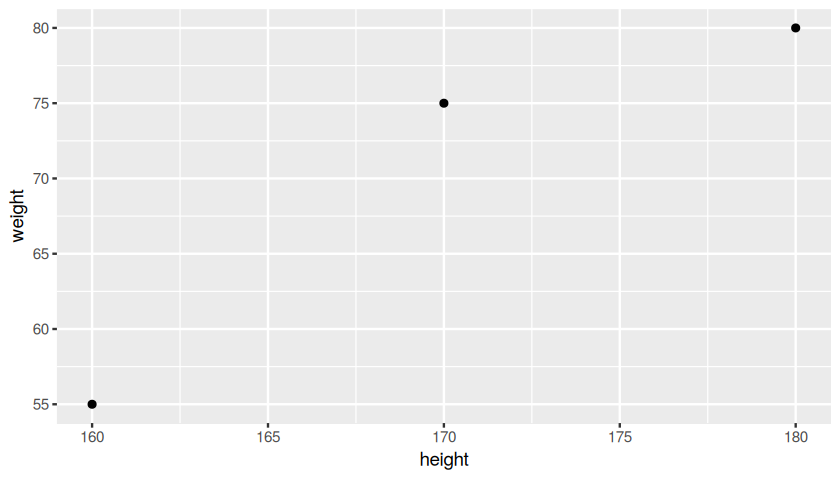

In [37]:
options(repr.plot.width = 7, repr.plot.height = 4)
ggplot(data = tbp) + geom_point(aes(x = height, y = weight))

### `geom_line()`

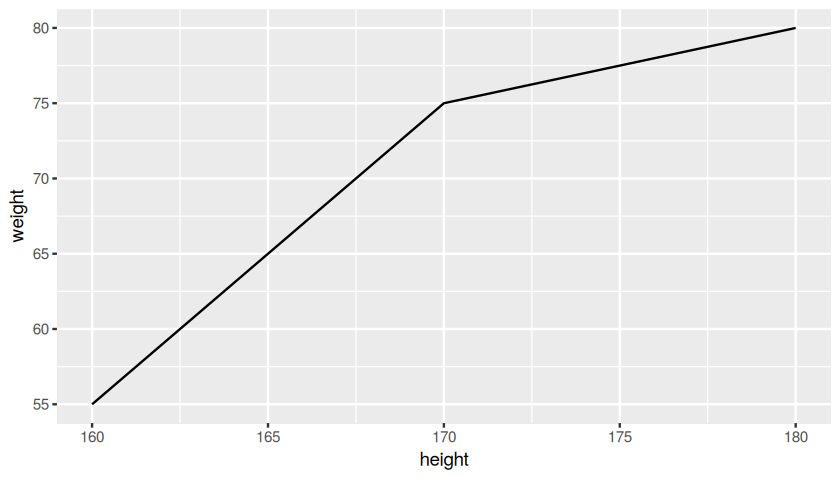

In [38]:
ggplot(data = tbp) + geom_line(aes(x = height, y = weight))

### Combining layers and mapping a colour

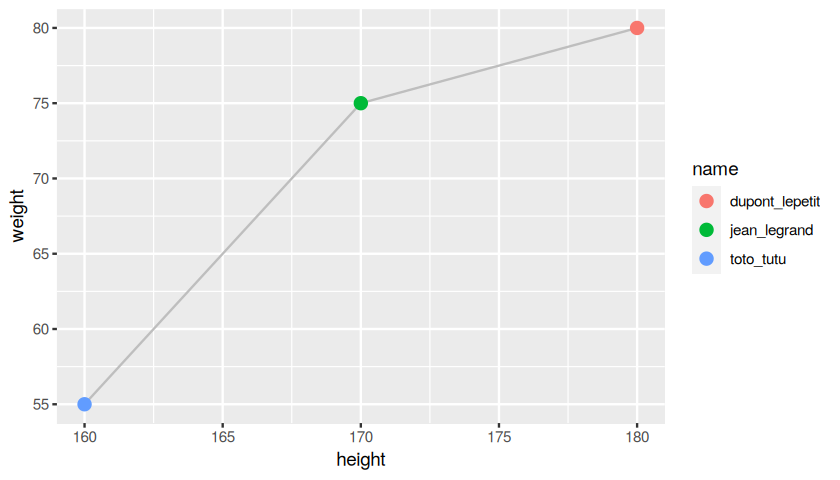

In [39]:
ggplot(data = tbp) +
  geom_line(aes(x = height, y = weight), color = "grey") +
  geom_point(aes(x = height, y = weight, color = name), size = 3)

<div style="background-color: #e7f3fe; border-left: 6px solid #2196F3; padding: 10px;">
    ℹ️ <strong>Note</strong><br>
    <code>color = "grey"</code> <b>outside</b> <code>aes()</code> sets a constant. <code>color = name</code> <b>inside</b> <code>aes()</code> maps a variable to the colour.
</div>

### Distributions: `geom_histogram()` and `geom_density()`

Simulated depth for two samples, with a minimum-depth threshold (`geom_vline()`).

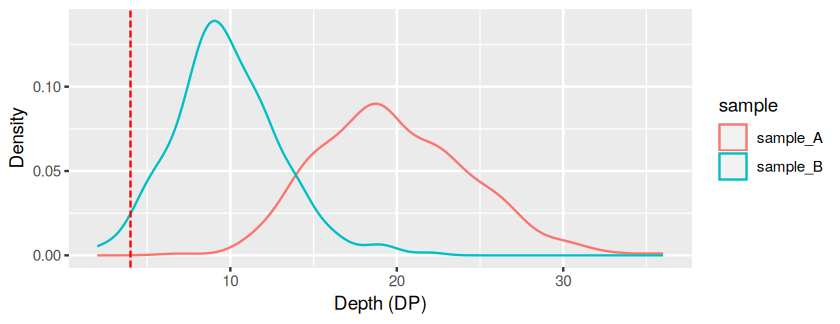

In [40]:
options(repr.plot.width = 7, repr.plot.height = 2.7)
set.seed(42)
depth <- tibble(sample = rep(c("sample_A", "sample_B"), each = 300),
                DP     = c(rpois(300, lambda = 20), rpois(300, lambda = 10)))

ggplot(depth, aes(x = DP, color = sample)) +
  geom_density() +
  geom_vline(xintercept = 4, color = "red", linetype = "longdash") +
  labs(x = "Depth (DP)", y = "Density")

### Histogram

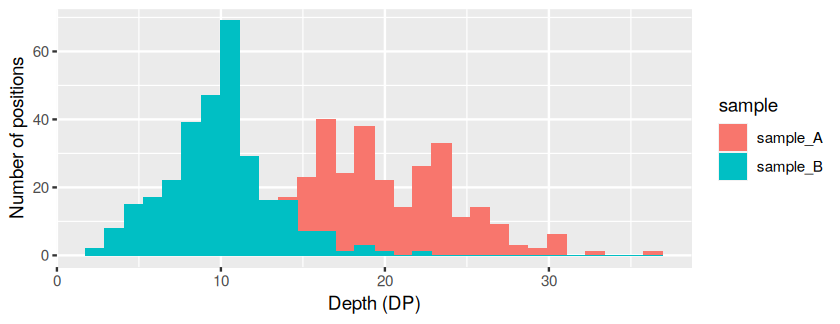

In [41]:
ggplot(depth, aes(x = DP, fill = sample)) +
  geom_histogram(bins = 30, position = "identity") +
  labs(x = "Depth (DP)", y = "Number of positions")

## VII - Exercises

<div style="background-color: #fbefff; border-left: 6px solid #8250df; padding: 10px;">
    ❓ <strong>Question</strong><br>
    Using the tibble <code>depth</code> defined above:<br>
1. How many positions have <code>DP &lt; 4</code> in each sample?<br>
2. Compute the mean and the median depth per sample.<br>
3. Add a column <code>low_cov</code> equal to <code>"low"</code> if <code>DP &lt; 10</code>, else <code>"ok"</code>, then count the rows per sample and per class.
</div>

<div style="background-color: #fbefff; border-left: 6px solid #8250df; padding: 10px;">
    ❓ <strong>Question</strong><br>
    Using the vector <code>alt &lt;- c("A", "AT", "C,T", "G", "TCC")</code>:<br>
build a tibble with the columns <code>alt</code>, <code>n_alleles</code> (1 + number of commas) and <code>type</code> (<code>"SNV"</code> if the length is 1 and there is no comma, <code>"multi-allelic"</code> if there is a comma, otherwise <code>"INDEL"</code>).
</div>

**Solutions** (not shown in the slideshow)

In [42]:
depth %>% filter(DP < 4) %>% count(sample)

depth %>% group_by(sample) %>% summarise(mean_DP = mean(DP), median_DP = median(DP))

depth %>%
  mutate(low_cov = if_else(DP < 10, "low", "ok")) %>%
  count(sample, low_cov)

sample,n
<chr>,<int>
sample_B,4


sample,mean_DP,median_DP
<chr>,<dbl>,<dbl>
sample_A,19.81667,19.0
sample_B,9.79000,9.5


sample,low_cov,n
<chr>,<chr>,<int>
sample_A,low,1
sample_A,ok,299
sample_B,low,150
sample_B,ok,150


In [43]:
alt <- c("A", "AT", "C,T", "G", "TCC")
tibble(alt = alt) %>%
  mutate(n_alleles = 1 + str_count(alt, ","),
         type = case_when(str_detect(alt, ",") ~ "multi-allelic",
                          str_length(alt) == 1 ~ "SNV",
                          TRUE                 ~ "INDEL"))

alt,n_alleles,type
<chr>,<dbl>,<chr>
A,1,SNV
AT,1,INDEL
"C,T",2,multi-allelic
G,1,SNV
TCC,1,INDEL


## Summary

* **Tidy data**: one variable per column, one observation per row, one value per cell; `tibble` is the table format.
* **`tidyr`**: `unite` / `separate` to merge or split columns, `pivot_longer` / `pivot_wider` to change the shape.
* **`dplyr`**: `filter` (rows), `select` (columns), `mutate` (new columns, with `if_else` / `case_when`), `group_by` + `summarise` / `count`, and the `*_join` family.
* **`stringr`**: `str_detect`, `str_length`, `str_extract`, `str_remove` to handle text fields such as ALT or ANN.
* **`ggplot2`**: data + `aes()` + `geom_*()`, layers added with `+`.
* Chain the steps with the pipe `%>%`.

**Next**: the same tools applied to a VCF file (notebook *05_Manipulating_VCF_post_calling*).